In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv, j0, j1, jv, jvp
from scipy.signal import savgol_filter

import matplotlib.pyplot as plt
import matplotlib.colors as colors


from transmission_maps import point_signal_SBW, point_signal_DBW
from scenery_generation import generate_scenery
from cross_correlation import cross_corr_coeff, cross_corr_coeff_merged

from matplotlib.colors import LogNorm


In [2]:
# =================== general parameters ====================
# not relevant for the NN
Npix = 100
fov_as = 0.3 # [arcsec]
fov_rad =  fov_as * (np.pi / 180) / 3600 # [rad]

time = 30 * 3600 # [s]
read_time = 1000 #[s]
N = int(time / read_time)

R = 20
lambda_min = 4e-6
lambda_max = 18.5e-6

alpha = np.linspace(-fov_as, fov_as, Npix)
beta = np.linspace(-fov_as, fov_as, Npix)
ALPHA, BETA = np.meshgrid(alpha, beta, indexing='ij') # [as]


# ================== Instrument parameters ===================
# as info for NN but not being retrieved (only input, not output)
baseline =20 # [m]
t = np.linspace(0, time, N)
Omega = (2 / time) * 2 * np.pi #  [rad/s]
lambdas = np.logspace(np.log10(lambda_min), np.log10(lambda_max), int(R * np.log(lambda_max/lambda_min) + 0.5), base = 10)

In [3]:
T_SBW_lambda_scenery = point_signal_SBW(t, ALPHA, BETA, baseline, lamda_ref=lambdas, Omega = Omega)

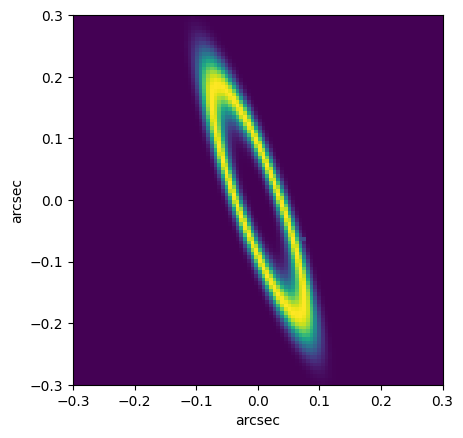

In [5]:
# =================== Scenery parameters ====================
sep_planet_as = 0.1 # [arcsec]
phase_planet = 50 # [deg] [0,180) for single-bracewell, [0,360) for double-bracewell
flux_planet = 1e6 

inc_exozodi = 80 # [deg] [0,90]
phi_exozodi = 20 # [deg] [0,180) for single-bracewell, [0,360) for double-bracewell
r0_exozodi = 0.2

sig_exozodi = 0.04
flux_exozodi = 1e6

# =================== Generate the scenery =============================== 
IM = generate_scenery(sep_planet_as, phase_planet, flux_planet, inc_exozodi, phi_exozodi, r0_exozodi, sig_exozodi, flux_exozodi, ALPHA, BETA)

# ============== Plot the Scenery ==============================
plt.figure()
plt.imshow(IM, cmap='viridis', extent = (-fov_as, fov_as, -fov_as, fov_as))
plt.xlabel("arcsec")
plt.ylabel("arcsec")
plt.show()
plt.close()

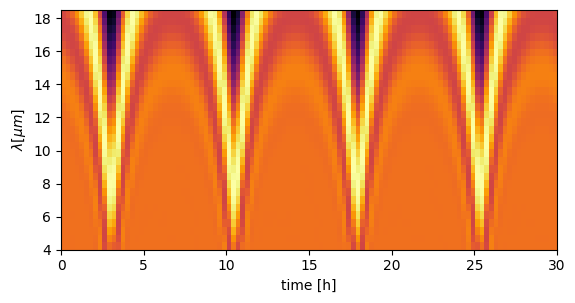

In [6]:

signal = np.sum(T_SBW_lambda_scenery * IM[None, None, :, :], axis=(2,3)) 

# ================== Plot signal ==================
plt.figure()
plt.imshow(signal, extent=(t[0]/3600, t[-1]/3600, lambdas[0]*1e6, lambdas[-1]*1e6),  cmap='inferno', origin = 'lower')
plt.xlabel("time [h]")
plt.ylabel(r"$\lambda [\mu m]$")
plt.show()
plt.close()

## Signal Processing

### Time dependent Transmission Map for the signal of the entire field of view

In [7]:


def combined_plot(IM, proj, proj_merged, vmin = None, vmax = None,  cmap = 'viridis'):


    fig, ax = plt.subplots(1, 7, figsize = (15, 8))
    N_l = len(ax)-2
    step = int(len(lambdas)/N_l)
    print(N_l, step)
    for i in range(N_l):
        ax[i].imshow(proj[i*step,:,:], extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = cmap,  vmin=vmin, vmax=vmax)
        ax[i].set_title(rf"$\lambda$ = {np.round(1e6*lambdas[i*step],2)} $\mu m$")
    ax[-2].imshow(proj_merged, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = cmap,  vmin=vmin, vmax=vmax)
    ax[-1].imshow(IM, extent=(-fov_as, fov_as, -fov_as, fov_as), cmap = 'inferno')
    ax[-2].set_title(r"All $\lambda$")
    ax[-1].set_title(r"Target Image")
    for i in range(ax.shape[0]):
        ax[i].set_xticks([])
        ax[i].set_yticks([])
    plt.show()
    plt.close()


5 6


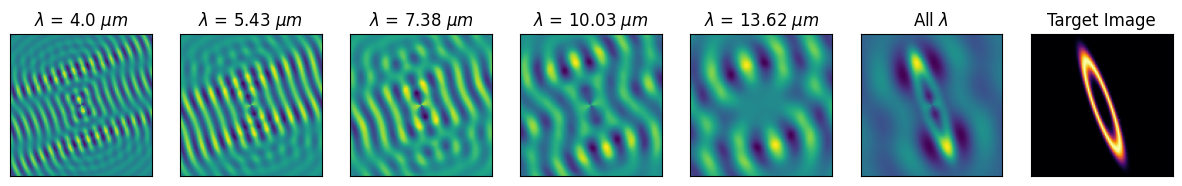

In [8]:
proj = cross_corr_coeff(signal, T_SBW_lambda_scenery, centered = True)
proj_merged = cross_corr_coeff_merged(signal, T_SBW_lambda_scenery, centered = True)
#combined_plot(IM,proj, proj_merged, vmin=-1, vmax =1, cmap = 'coolwarm_r')
combined_plot(IM,proj, proj_merged)


# Plots

In [12]:

baseline = 8
t = np.linspace(0, 2*np.pi, 1000)/Omega

idx_alpha = 30
idx_beta = 30
idx_lambda = 15
idx_time = 0
r0 = np.sqrt(alpha[idx_alpha]**2 + beta[idx_beta]**2) # [ arcsec ]
#r0 = 0.07
circle = np.asarray([np.sin(np.linspace(0, 2*np.pi, 100)),  np.cos(np.linspace(0, 2*np.pi, 100))])* r0


inv_range = baseline / lambdas / 3600 / 180 * np.pi * r0
inv_l = inv_range[idx_lambda] 

S_SBW_lambda_scenery = point_signal_SBW(t, alpha[idx_alpha], beta[idx_beta], baseline, lamda_ref=lambdas, Omega = Omega)
T_SBW_lambda_scenery = point_signal_SBW(t[idx_time], ALPHA, BETA, baseline, lamda_ref=lambdas[idx_lambda], Omega = Omega)
S_DBW_lambda_scenery = point_signal_DBW(t, alpha[idx_alpha], beta[idx_beta], baseline, lamda_ref=lambdas, Omega = Omega, q = 6)
T_DBW_lambda_scenery = point_signal_DBW(t[idx_time], ALPHA, BETA, baseline, lamda_ref=lambdas[idx_lambda], Omega = Omega, q = 6)

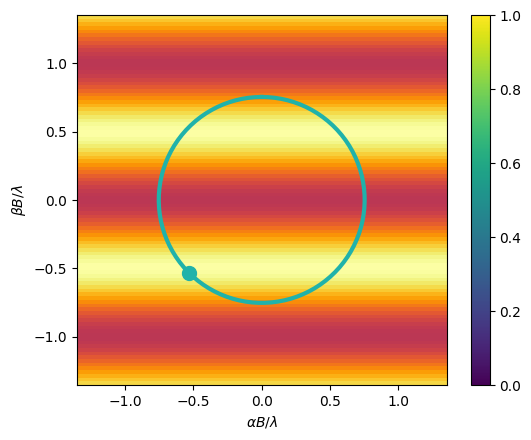

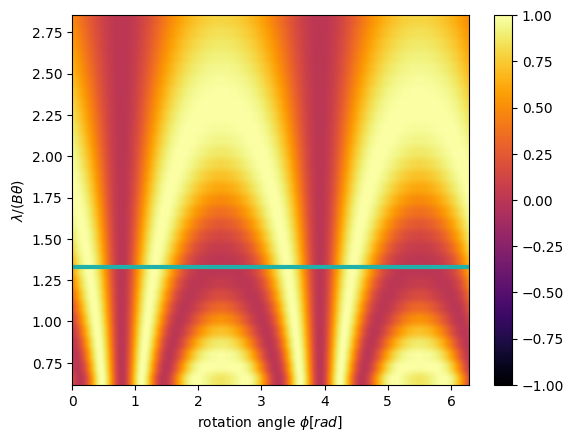

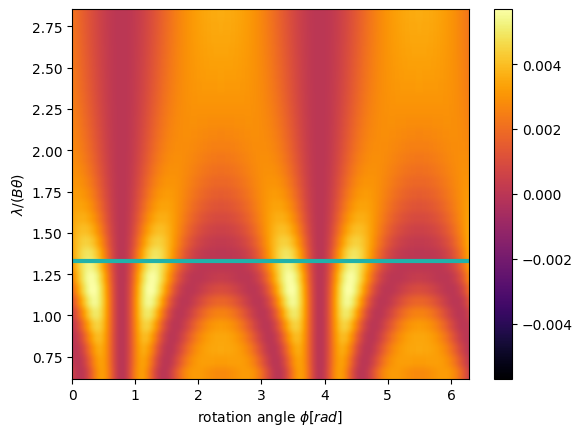

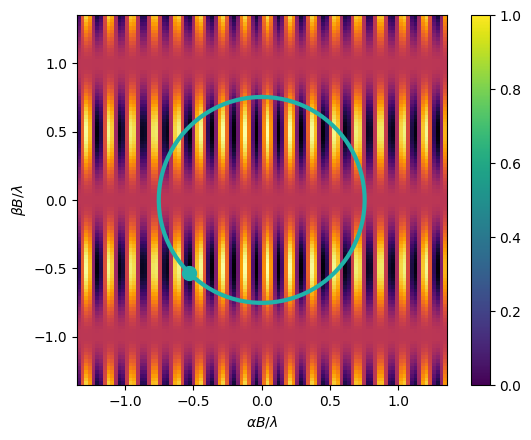

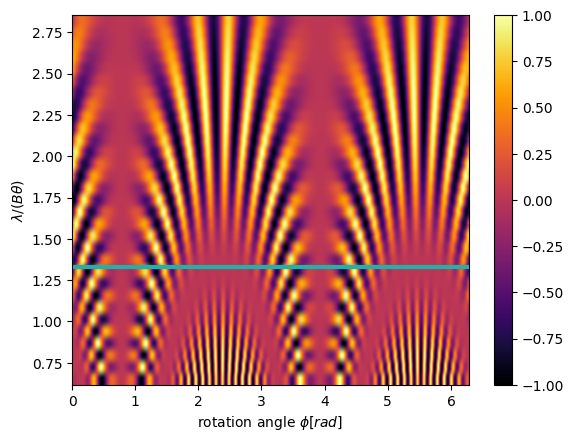

In [36]:
plt.subplots()
plt.imshow(T_SBW_lambda_scenery,extent = (alpha[0]/r0 *inv_l, alpha[-1]/r0 * inv_l, beta[0]/r0 * inv_l, beta[-1]/r0 * inv_l), cmap = 'inferno', vmin = -1, vmax = 1)
plt.scatter(alpha[idx_alpha]/r0 * inv_l, beta[idx_beta]/r0 * inv_l, color = 'lightseagreen', s = 100)
plt.plot(circle[0,:]/r0 * inv_l, circle[1,:]/r0 * inv_l , "-",color = 'lightseagreen', lw = 3)
plt.xlabel(r"$\alpha B / \lambda$")
plt.ylabel(r"$\beta B / \lambda$")
plt.colorbar()
plt.savefig('plots/sbw_transmission.png', transparent=True)
plt.show()
plt.close()

plt.subplots()
plt.imshow(S_SBW_lambda_scenery, extent = (t[0]*Omega, t[-1]*Omega, 1/(inv_range[0]), 1/(inv_range[-1]) ), aspect = 'auto', origin = 'lower', cmap = 'inferno', vmin = -1, vmax = 1)
plt.plot(t*Omega, 1/(inv_l) * np.ones_like(t) , "-",color = 'lightseagreen', lw = 3)
plt.xlabel(r"rotation angle $\phi[rad]$")
plt.ylabel(r"$\lambda / (B \theta)$")
plt.colorbar()
plt.savefig('plots/sbw_point_signal.png', transparent=True)
plt.show()
plt.close()

plt.subplots()
S_SBW_lambda_norm = S_SBW_lambda_scenery / np.sum(S_SBW_lambda_scenery[:,:int(len(t)/2)], axis = 1)[:,None]
plt.imshow(S_SBW_lambda_norm, extent = (t[0]*Omega, t[-1]*Omega, 1/(inv_range[0]), 1/(inv_range[-1]) ), aspect = 'auto', origin = 'lower', cmap = 'inferno', vmin = -np.max(S_SBW_lambda_norm), vmax = np.max(S_SBW_lambda_norm))
plt.plot(t*Omega, 1/(inv_l) * np.ones_like(t) , "-",color = 'lightseagreen', lw = 3)
plt.xlabel(r"rotation angle $\phi[rad]$")
plt.ylabel(r"$\lambda / (B \theta)$")
plt.colorbar()
plt.savefig('plots/sbw_point_signal_norm.png', transparent=True)
plt.show()
plt.close()

plt.subplots()
plt.imshow(T_DBW_lambda_scenery,extent = (alpha[0]/r0 *inv_l, alpha[-1]/r0 * inv_l, beta[0]/r0 * inv_l, beta[-1]/r0 * inv_l), cmap = 'inferno', vmin = -1, vmax = 1)
plt.scatter(alpha[idx_alpha]/r0 * inv_l, beta[idx_beta]/r0 * inv_l, color = 'lightseagreen', s = 100)
plt.plot(circle[0,:]/r0 * inv_l, circle[1,:]/r0 * inv_l , "-",color = 'lightseagreen', lw = 3)
plt.xlabel(r"$\alpha B / \lambda$")
plt.ylabel(r"$\beta B / \lambda$")
plt.colorbar()
plt.savefig('plots/dbw_transmission.png', transparent=True)
plt.show()
plt.close()

plt.subplots()
plt.imshow(S_DBW_lambda_scenery, extent = (t[0]*Omega, t[-1]*Omega, 1/(inv_range[0]), 1/(inv_range[-1]) ), aspect = 'auto', origin = 'lower', cmap = 'inferno', vmin = -1, vmax = 1)
plt.plot(t*Omega, 1/(inv_l) * np.ones_like(t) , "-",color = 'lightseagreen', lw = 3)
plt.xlabel(r"rotation angle $\phi[rad]$")
plt.ylabel(r"$\lambda / (B \theta)$")
plt.colorbar()
plt.savefig('plots/dbw_point_signal.png', transparent=True)
plt.show()
plt.close()




In [31]:
S_SBW_lambda_scenery.shape

(31, 1000)

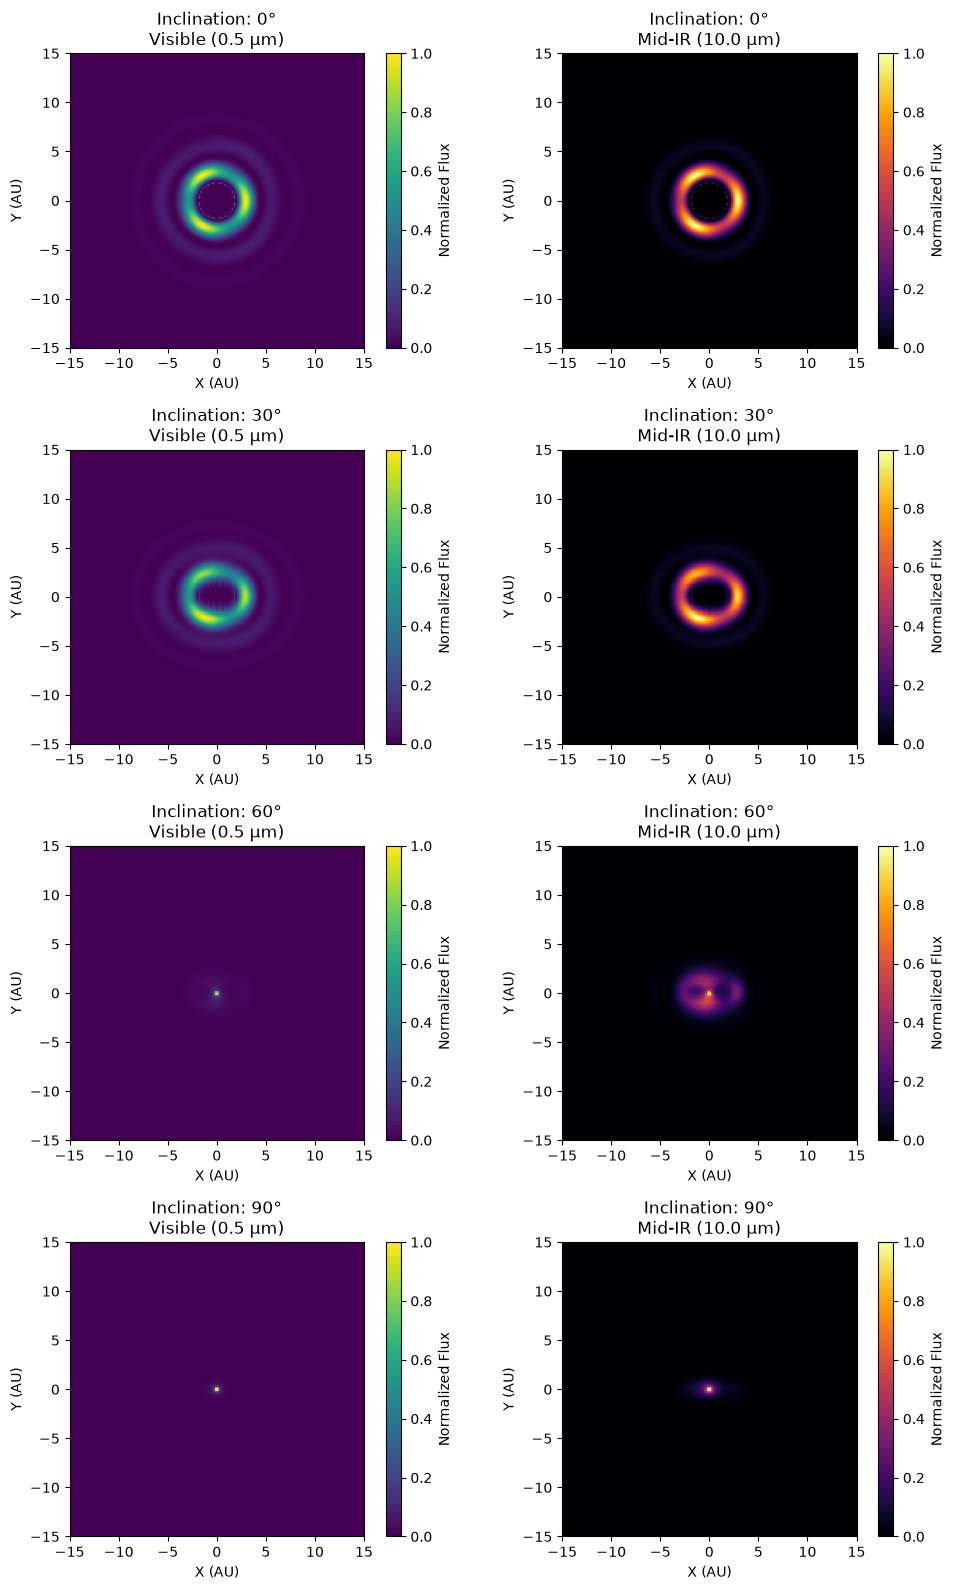

In [ ]:

from scipy.special import jn  # Bessel function of first kind

# 1. Setup 3D Grid Parameters (X, Y, Z)
grid_res = 160             # Resolution of the 3D cube
box_size = 15.0            # Boundaries from -15 to +15 AU
axis = np.linspace(-box_size, box_size, grid_res)
X, Y, Z = np.meshgrid(axis, axis, axis, indexing='ij')

# 2. Generate the Base 3D Physical Disk Structure
def generate_3d_disk_density(clumpy=True):
    # Convert flat coordinates to cylindrical coordinates (r, theta, z)
    R_cyl = np.sqrt(X**2 + Y**2) + 1e-6
    Theta = np.arctan2(Y, X)
    
    # Radial structural profile using a 0th-order Bessel function
    k_radial = 1.2
    radial_profile = (jn(0, k_radial * R_cyl))**2 * np.exp(-R_cyl / 6.0)
    radial_profile[R_cyl < 1.8] = 0  # Clear out inner stellar zone
    
    # Structural Clumps using a 3rd-order Bessel-Fourier term
    if clumpy:
        m_clumps = 3
        clump_factor = jn(m_clumps, k_radial * R_cyl) * np.cos(m_clumps * Theta)
        density_profile = radial_profile * (1.0 + 0.8 * clump_factor)
    else:
        density_profile = radial_profile

    # Vertical distribution profile (Gaussian disk scale height H = 0.8 AU)
    H = 0.8 
    vertical_profile = np.exp(-0.5 * (Z / H)**2)
    
    # Combine into a final 3D Density Grid
    return np.clip(density_profile * vertical_profile, 0, None)

# 3. Rotate the 3D Grid & Integrate Along the Line of Sight
def project_disk_at_inclination(density_3d, inclination_deg):
    angle_rad = np.radians(inclination_deg)
    
    # Define standard rotation matrix coordinates around X-axis
    # Rotates the viewing coordinates to look through the cube at an angle
    Y_rot = Y * np.cos(angle_rad) - Z * np.sin(angle_rad)
    Z_rot = Y * np.sin(angle_rad) + Z * np.cos(angle_rad)
    
    # Map coordinates from grid units to array index units
    idx_X = ((X + box_size) / (2.0 * box_size) * (grid_res - 1)).astype(int)
    idx_Y = ((Y_rot + box_size) / (2.0 * box_size) * (grid_res - 1)).astype(int)
    idx_Z = ((Z_rot + box_size) / (2.0 * box_size) * (grid_res - 1)).astype(int)
    
    # Keep indices strictly inside array boundaries
    mask = (idx_Y >= 0) & (idx_Y < grid_res) & (idx_Z >= 0) & (idx_Z < grid_res)
    
    # Map original density values into the newly rotated 3D grid spatial array
    rotated_density = np.zeros_like(density_3d)
    rotated_density[mask] = density_3d[idx_X[mask], idx_Y[mask], idx_Z[mask]]
    
    # Numerical line-of-sight integration: Collapse the Z axis to get a 2D image
    integrated_2d_density = np.sum(rotated_density, axis=2)
    return integrated_2d_density

# 4. Multi-Wavelength Flux Calculations
def calculate_wavelength_flux(density_2d, wavelength_um):
    # Set up a 2D distance map from the central stellar core
    X_2d, Y_2d = np.meshgrid(axis, axis, indexing='ij')
    R_2d = np.sqrt(X_2d**2 + Y_2d**2) + 1e-6
    
    # Radial profile of dust grain temperature: drops with distance (T ~ R^-0.5)
    T_profile = 280.0 * (R_2d / 5.0)**(-0.5)
    
    if wavelength_um < 1.0:
        # Visible Light: Dominated by scattered stellar flux (falls off as 1/R^2)
        flux = density_2d * (1.0 / R_2d**2)
    else:
        # Infrared Light: Thermal dust emission via Planck's Law approximation
        h, c, kB = 6.626e-34, 3.0e8, 1.38e-23
        freq = c / (wavelength_um * 1e-6)
        exponent = (h * freq) / (kB * T_profile)
        blackbody = (2.0 * h * freq**3 / c**2) / (np.exp(np.clip(exponent, 0, 700)) - 1.0)
        flux = density_2d * blackbody
        
    return flux / np.max(flux)  # Normalized output 

# 5. Generate Simulation Grid Matrix (Angles: 0, 30, 60, 90)
inclinations = [0, 30, 60, 90]
wavelengths = {"Visible (0.5 µm)": 0.5, "Mid-IR (10.0 µm)": 10.0}

# Pre-generate our 3D master clumpy disk array
master_3d_disk = generate_3d_disk_density(clumpy=True)

fig, axes = plt.subplots(4, 2, figsize=(10, 16))
plt.subplots_adjust(wspace=0.3, hspace=0.4)

for row_idx, inc in enumerate(inclinations):
    # Perform 3D line-of-sight rotation calculation for this specific angle
    density_surface = project_disk_at_inclination(master_3d_disk, inc)
    
    for col_idx, (wave_name, wave_val) in enumerate(wavelengths.items()):
        ax = axes[row_idx, col_idx]
        
        # Calculate localized physical wavelength emission properties
        flux_map = calculate_wavelength_flux(density_surface, wave_val)
        
        # Plot styling matrix
        cmap = "viridis" if wave_val < 1.0 else "inferno"
        im = ax.imshow(flux_map.T, extent=[-box_size, box_size, -box_size, box_size], 
                       cmap=cmap, origin='lower')
        
        ax.set_title(f"Inclination: {inc}°\n{wave_name}")
        ax.set_xlabel("X (AU)")
        ax.set_ylabel("Y (AU)")
        fig.colorbar(im, ax=ax, label="Normalized Flux")

plt.tight_layout()
plt.show()


Text(0.5, 1.0, 'Intensity Pattern (FFT of Aperture)')

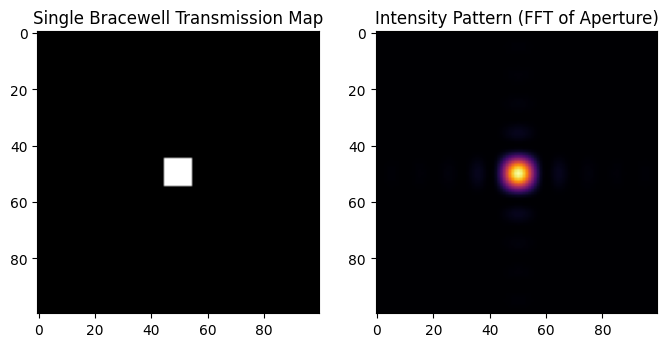

In [ ]:
# Single Bracewell Transmission Map

Aperture = np.zeros((100, 100))
Aperture[45:55, 45:55] = 1
Aperture_FFT = np.fft.fftshift(np.fft.fft2(Aperture))
Intensity = np.abs(Aperture_FFT)**2


fig, ax = plt.subplots(1, 2, figsize=(8, 12))
ax[0].imshow(Aperture, cmap='gray')
ax[0].set_title('Single Bracewell Transmission Map')
#ax[0].colorbar()
ax[1].imshow(Intensity, cmap='inferno')
ax[1].set_title('Intensity Pattern (FFT of Aperture)')
#ax[1].colorbar()



(-2.0, 2.0)

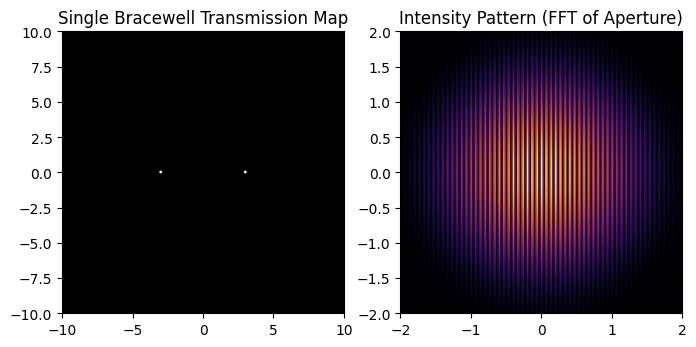

In [ ]:
# Single Bracewell Transmission Map
x = np.linspace(-10, 10, 1000)
y = np.linspace(-10, 10, 1000)
X, Y = np.meshgrid(x, y)
Aperture = np.zeros_like(X)
Aperture[np.sqrt((X-3)**2 + Y**2) < 0.1] = 1
Aperture[np.sqrt((X+3)**2 + Y**2) < 0.1] = 1

Aperture_FFT = np.fft.fftshift(np.fft.fft2(Aperture))
Intensity = np.abs(Aperture_FFT)**2

fig, ax = plt.subplots(1, 2, figsize=(8, 12))
ax[0].imshow(Aperture, cmap='gray', extent=[-10, 10, -10, 10])
ax[0].set_title('Single Bracewell Transmission Map')
ax[1].imshow(Intensity, cmap='inferno', extent=[-10, 10, -10, 10])
ax[1].set_title('Intensity Pattern (FFT of Aperture)')
ax[1].set_xlim([-2, 2])
ax[1].set_ylim([-2, 2])

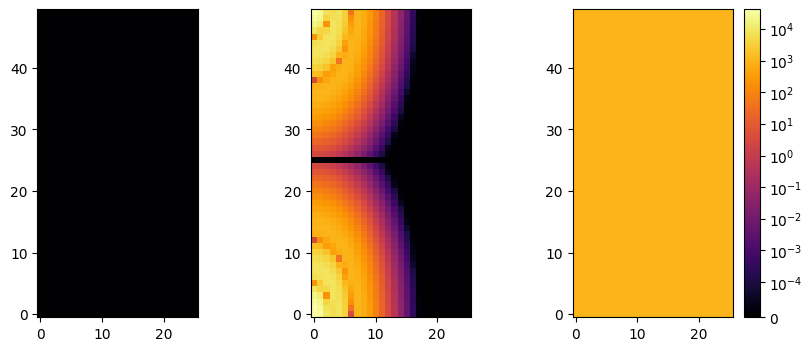

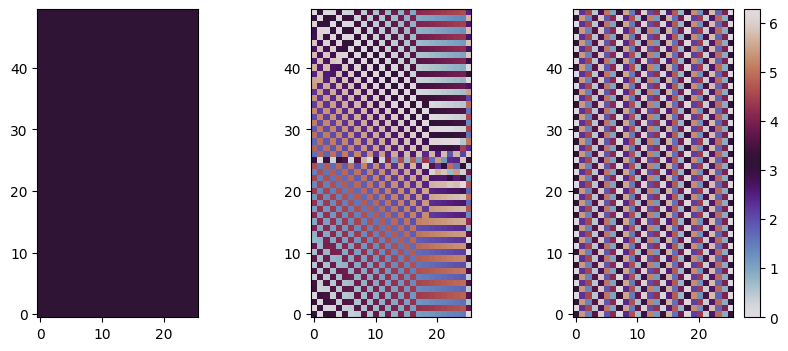

In [ ]:
IM_star_fft = np.fft.rfft2(IM_star)
IM_exozodi_fft = np.fft.rfft2(IM_exozodi)
IM_planet_fft = np.fft.rfft2(IM_planet)

vmin = min(np.min(np.abs(IM_star_fft)), np.min(np.abs(IM_exozodi_fft)), np.min(np.abs(IM_planet_fft)))
vmax = max(np.max(np.abs(IM_star_fft)), np.max(np.abs(IM_exozodi_fft)), np.max(np.abs(IM_planet_fft)))
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(np.abs(IM_star_fft), origin = 'lower', cmap='inferno', norm = colors.SymLogNorm(vmin=vmin, vmax=vmax, linthresh=0.0001))
ax[1].imshow(np.abs(IM_exozodi_fft), origin = 'lower', cmap='inferno', norm = colors.SymLogNorm(vmin=vmin, vmax=vmax, linthresh=0.0001)) 
ax[2].imshow(np.abs(IM_planet_fft), origin = 'lower', cmap='inferno', norm = colors.SymLogNorm(vmin=vmin, vmax=vmax, linthresh=0.0001)) 
cbar = plt.colorbar(ax[2].images[0], ax=ax[2])

vmin = min(np.min(np.abs(IM_star_fft)), np.min(np.abs(IM_exozodi_fft)), np.min(np.abs(IM_planet_fft)))
vmax = max(np.max(np.abs(IM_star_fft)), np.max(np.abs(IM_exozodi_fft)), np.max(np.abs(IM_planet_fft)))
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(np.angle(IM_star_fft) + np.pi, origin = 'lower', cmap='twilight', vmin = 0, vmax = 2*np.pi)
ax[1].imshow(np.angle(IM_exozodi_fft) + np.pi, origin = 'lower', cmap='twilight', vmin = 0, vmax = 2*np.pi) 
ax[2].imshow(np.angle(IM_planet_fft) + np.pi, origin = 'lower', cmap='twilight', vmin = 0, vmax = 2*np.pi) 
cbar = plt.colorbar(ax[2].images[0], ax=ax[2])

In [ ]:
'''N = len(t)
freq_full = np.fft.rfftfreq(N, d=t[1]-t[0])
freq = np.abs(freq_full)

def compute_fft(signal):
    signal_fft = np.fft.rfft(signal, axis = 1)
    amp = 2.0 / N * np.abs(signal_fft) 
    phase = np.angle(signal_fft)
    return amp, phase


amp_p, phase_p = compute_fft(signal_planet)
amp_ez, phase_ez = compute_fft(signal_exozodi)
amp_both, phase_both = compute_fft(signal_both)

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
vmin = min(np.min(amp_p), np.min(amp_ez), np.min(amp_both))
vmax = max(np.max(amp_p), np.max(amp_ez), np.max(amp_both))

ax[0].imshow(amp_p,  extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower', norm = colors.LogNorm(vmin=vmin, vmax=vmax))
ax[1].imshow(amp_ez,extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower', norm = colors.LogNorm(vmin=vmin, vmax=vmax))
ax[2].imshow(amp_both,extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower', norm = colors.LogNorm(vmin=vmin, vmax=vmax))
ax[0].set_title('Amplitude with Planet')
ax[1].set_title('Amplitude with Exozodi')
ax[2].set_title('Amplitude with Both')
# add colorbar
cbar = plt.colorbar(ax[2].images[0], ax=ax[2])

fig, ax = plt.subplots(1, 3, figsize=(18, 4))

vmin = min(np.min(phase_p), np.min(phase_ez), np.min(phase_both))
vmax = max(np.max(phase_p), np.max(phase_ez), np.max(phase_both))

ax[0].imshow(phase_p, vmin = vmin, vmax = vmax, extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='twilight', origin = 'lower')
ax[1].imshow(phase_ez, vmin = vmin, vmax = vmax, extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='twilight', origin = 'lower')
ax[2].imshow(phase_both, vmin = vmin, vmax = vmax, extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='twilight', origin = 'lower')
ax[0].set_title('Phase with Planet')
ax[1].set_title('Phase with Exozodi')
ax[2].set_title('Phase with Both')
# add colorbar
cbar = plt.colorbar(ax[2].images[0], ax=ax[2])'''



"N = len(t)\nfreq_full = np.fft.rfftfreq(N, d=t[1]-t[0])\nfreq = np.abs(freq_full)\n\ndef compute_fft(signal):\n    signal_fft = np.fft.rfft(signal, axis = 1)\n    amp = 2.0 / N * np.abs(signal_fft) \n    phase = np.angle(signal_fft)\n    return amp, phase\n\n\namp_p, phase_p = compute_fft(signal_planet)\namp_ez, phase_ez = compute_fft(signal_exozodi)\namp_both, phase_both = compute_fft(signal_both)\n\nfig, ax = plt.subplots(1, 3, figsize=(18, 4))\nvmin = min(np.min(amp_p), np.min(amp_ez), np.min(amp_both))\nvmax = max(np.max(amp_p), np.max(amp_ez), np.max(amp_both))\n\nax[0].imshow(amp_p,  extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower', norm = colors.LogNorm(vmin=vmin, vmax=vmax))\nax[1].imshow(amp_ez,extent=(freq[0], freq[-1], lambdas[0]*1e6, lambdas[-1]*1e6), aspect='auto', cmap='inferno', origin = 'lower', norm = colors.LogNorm(vmin=vmin, vmax=vmax))\nax[2].imshow(amp_both,extent=(freq[0], freq[-1], lambdas[0]*1e6, lambd